# BeyondStyle — Steering Analysis

Automatic model/dataset detection from `.env` configuration.
Includes: Part A (Paired Data), Part B (Steering), Part C (Denoising Comparison).

In [1]:
import json, sys, warnings
import numpy as np
from pathlib import Path
from scipy import stats
warnings.filterwarnings("ignore")

sys.path.insert(0, str(Path.cwd().parent))

from src.config import get_model_path, get_model_id, get_steering_dir, get_figures_dir, get_dataset_path, extract_dataset_tag
from src.extraction import PairedHiddenStates
from src.steering import MeanDiffSteering
from src.visualization import (
    setup_style,
    plot_projection_distributions, plot_pca_embedding,
    plot_direction_similarity, plot_embedding_shift,
    plot_layer_metrics, plot_roc_curves, plot_separation_landscape,
    plot_denoise_comparison, plot_projection_violins,
)

setup_style()

# Auto-detect paths from .env
model_path = get_model_path()
model_id = get_model_id(model_path)
dataset = get_dataset_path()
dataset_tag = extract_dataset_tag(dataset)
STEER = get_steering_dir(model_id, dataset_tag=dataset_tag)
FIGS = get_figures_dir(model_id, dataset_tag=dataset_tag)
FIGS.mkdir(parents=True, exist_ok=True)
print(f"Model: {model_id}  |  Dataset: {dataset_tag}")
print(f"Steer dir: {STEER}")
print(f"Fig dir:   {FIGS}")

In [2]:
with open(STEER / "layer_metrics.json") as f:
    metrics = json.load(f)

method_keys = list(metrics["methods"].keys())
base_key = "mean_diff" if "mean_diff" in method_keys else method_keys[0]
LAYERS = sorted(int(k) for k in metrics["methods"][base_key])

states = {}
for ly in LAYERS:
    states[ly] = PairedHiddenStates.load(STEER / "states" / f"paired_states_layer{ly:02d}.pt")

# Load all method models
all_models = {}  # {method_key: {layer: model}}
for mk in method_keys:
    models = {}
    for ly in LAYERS:
        p = STEER / "models" / f"{mk}_layer{ly:02d}.pt"
        if p.exists():
            models[ly] = MeanDiffSteering.load(p)
    if models:
        all_models[mk] = models

md_models = all_models.get(base_key, {})

# Best layer by hull centroid distance, fallback to AUC
md = metrics["methods"][base_key]
if md[str(LAYERS[0])].get("hull_centroid_dist_norm") is not None:
    best_ly = max(LAYERS, key=lambda ly: md[str(ly)].get("hull_centroid_dist_norm", 0))
else:
    best_ly = max(LAYERS, key=lambda ly: md[str(ly)]["auc"])

print(f"Loaded {len(LAYERS)} layers  |  {states[LAYERS[0]].n_samples} samples  |  best = L{best_ly}")
print(f"Methods: {method_keys}")
has_ablation = len(method_keys) > 1
if has_ablation:
    print(f"  -> Ablation comparison available ({len(method_keys)} variants)")

---
# Part A — Paired Data Analysis
How do human and AI continuations differ in the model's representation space?

## A1 · Projection Distributions (Top-4 Layers)

  ✓ /home/hanyu/research/BeyondStyle/outputs/figures/fig01_projection_distributions.png


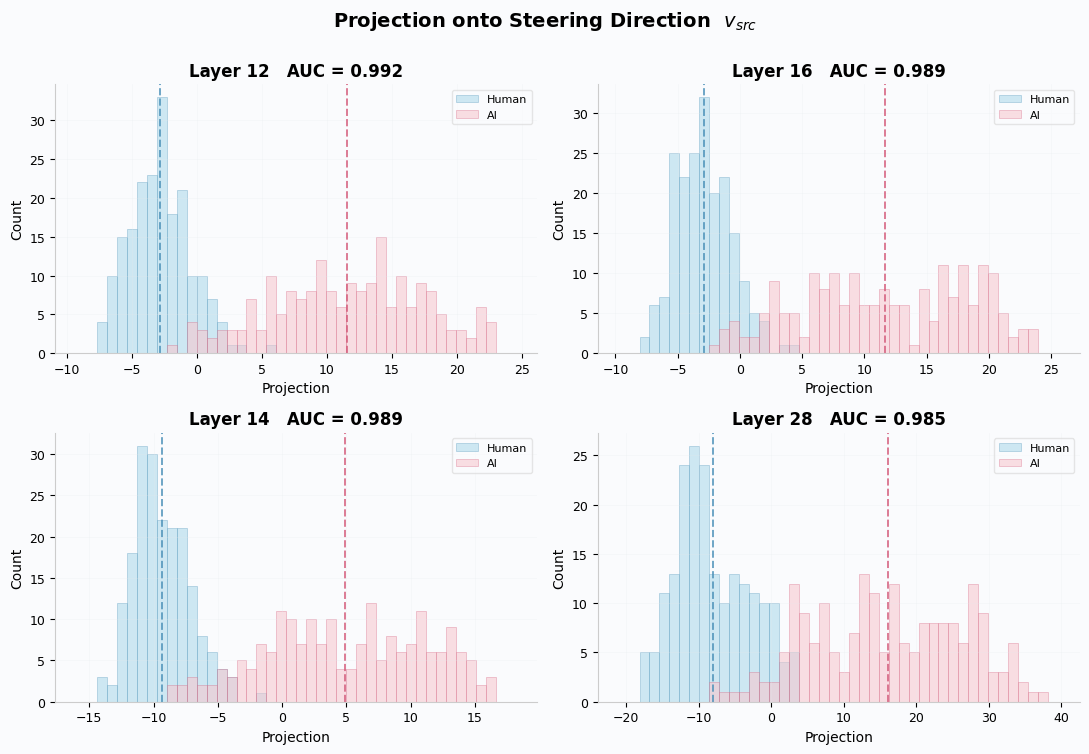

In [3]:
plot_projection_distributions(states, md_models, metrics, LAYERS, fig_dir=FIGS);

## A2 · PCA Embedding (Best Layer)

  ✓ /home/hanyu/research/BeyondStyle/outputs/figures/fig02_pca_embedding.png


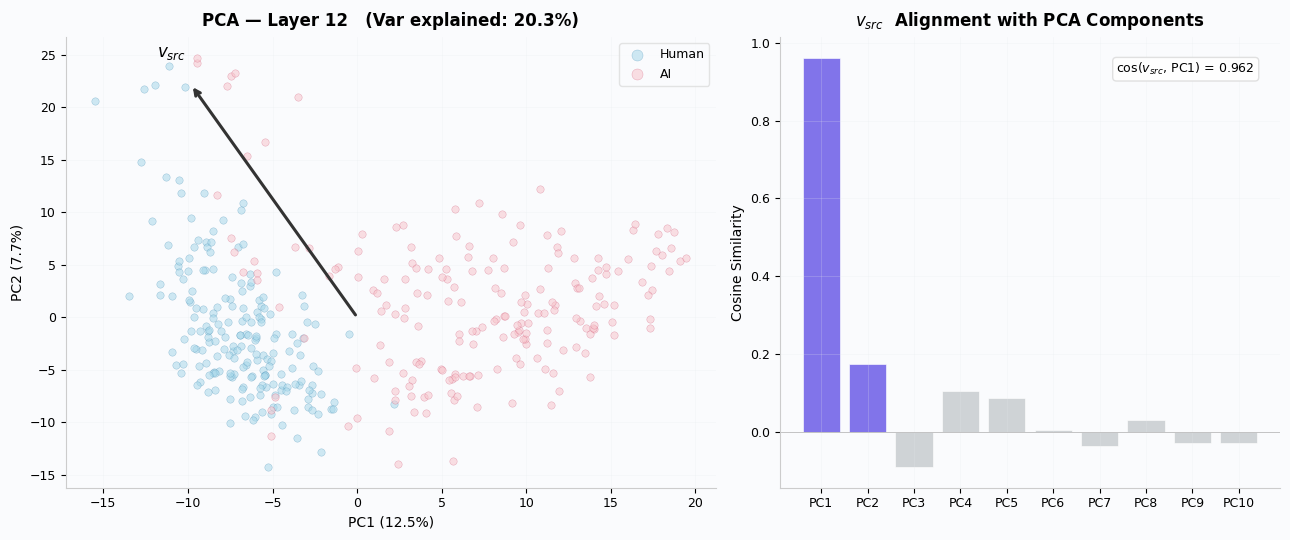

In [4]:
plot_pca_embedding(states, md_models, best_ly, fig_dir=FIGS);

## A3 · Steering Direction Similarity Across Layers

  ✓ /home/hanyu/research/BeyondStyle/outputs/figures/fig03_direction_similarity.png


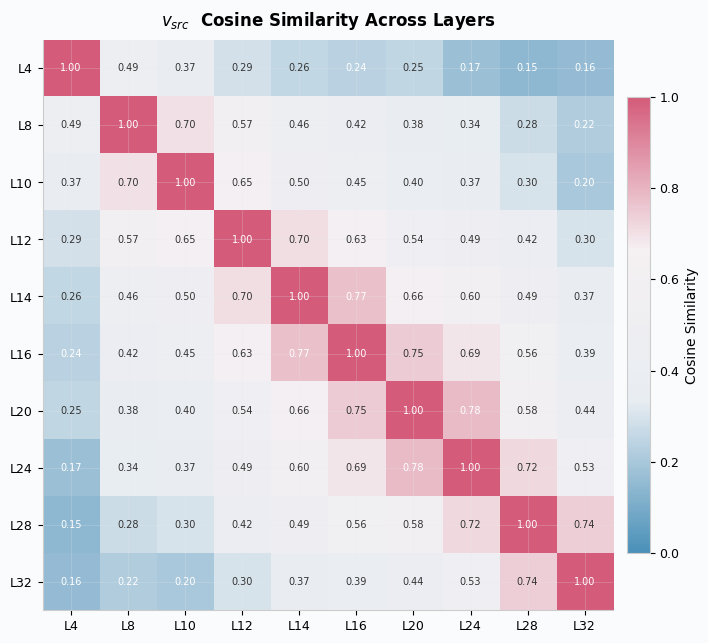

In [5]:
plot_direction_similarity(md_models, LAYERS, fig_dir=FIGS);

## A4 · Embedding Shift Under Steering
How does adding $\alpha \cdot v_{src}$ shift representations in PCA space?

  ✓ /home/hanyu/research/BeyondStyle/outputs/figures/fig04_embedding_shift.png


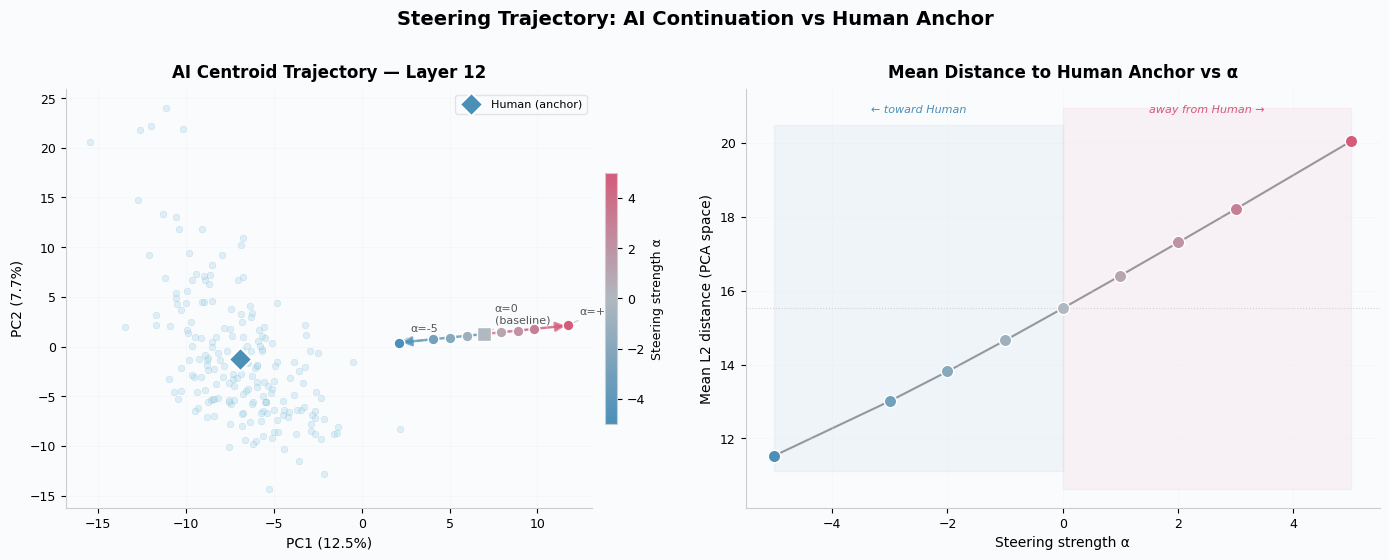

In [6]:
plot_embedding_shift(states, md_models, best_ly, fig_dir=FIGS);

## A5 · Statistical Significance

In [7]:
rows = []
for ly in LAYERS:
    ps = states[ly]
    v = md_models[ly].get_direction().cpu().float()
    hp = (ps.human.float() @ v).numpy()
    ap = (ps.ai.float() @ v).numpy()
    t, p = stats.ttest_ind(hp, ap)
    pooled = np.sqrt((hp.std()**2 + ap.std()**2) / 2)
    d = (ap.mean() - hp.mean()) / (pooled + 1e-10)
    size = "huge" if abs(d)>2 else "large" if abs(d)>0.8 else "medium" if abs(d)>0.5 else "small"
    rows.append((ly, t, p, d, size))

print(f"{'Layer':>6}  {'t-stat':>8}  {'p-value':>12}  {'Cohen d':>8}  {'Effect':>8}")
print("-"*50)
for ly, t, p, d, size in rows:
    print(f"{ly:>6}  {t:>8.2f}  {p:>12.2e}  {d:>8.2f}  {size:>8}")

 Layer    t-stat       p-value   Cohen d    Effect
--------------------------------------------------
     4    -22.16      5.28e-71      2.24      huge
     8    -29.71     3.22e-102      3.01      huge
    10    -29.99     2.59e-103      3.04      huge
    12    -32.28     3.43e-112      3.27      huge
    14    -30.28     1.88e-104      3.07      huge
    16    -28.90      5.76e-99      2.93      huge
    20    -26.48      3.53e-89      2.68      huge
    24    -27.30      1.68e-92      2.76      huge
    28    -29.00      2.28e-99      2.94      huge
    32    -24.55      4.00e-81      2.49      huge


---
# Part B — Steering Results
How well does each method and layer separate human vs AI, and how does steering affect generation?

## B1 · Layer-wise Metrics

  ✓ /home/hanyu/research/BeyondStyle/outputs/figures/fig05_layer_metrics.png


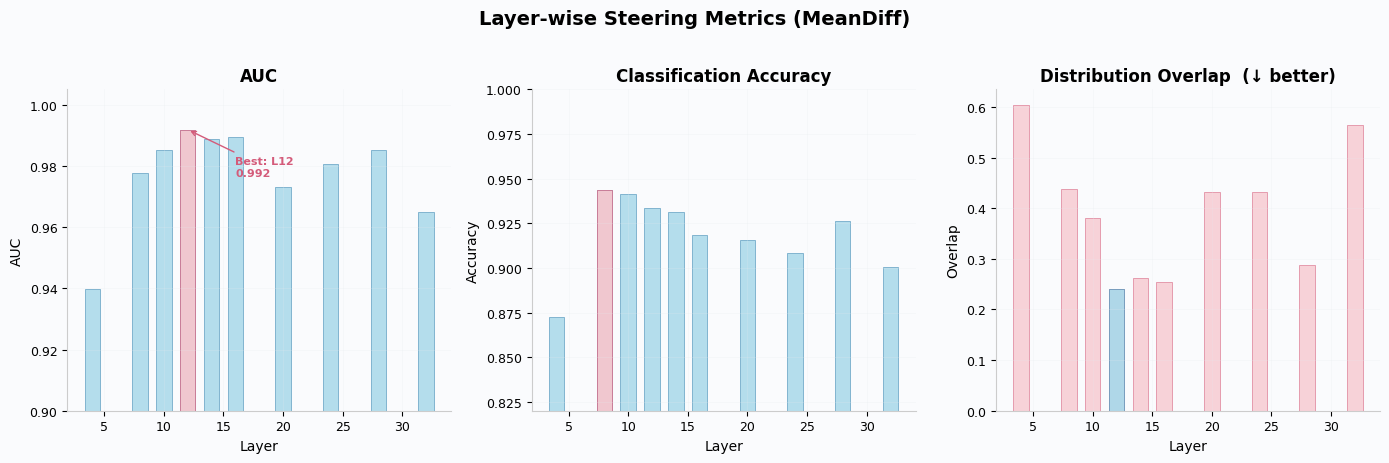

In [8]:
plot_layer_metrics(metrics, LAYERS, fig_dir=FIGS);

## B2 · ROC Curves

  ✓ /home/hanyu/research/BeyondStyle/outputs/figures/fig06_roc_curves.png


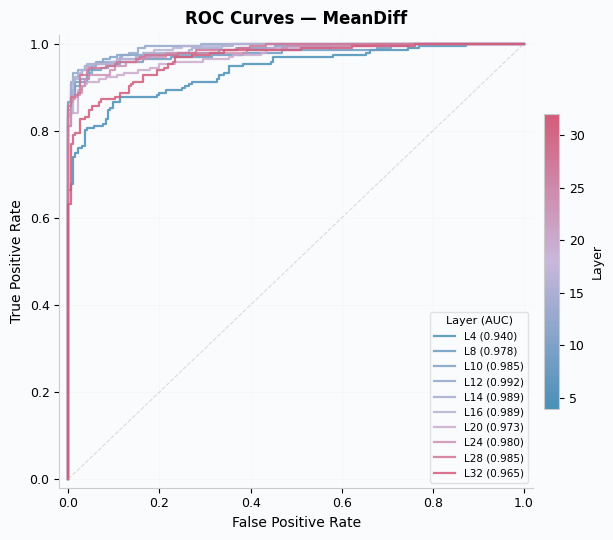

In [9]:
plot_roc_curves(states, md_models, metrics, LAYERS, fig_dir=FIGS);

## B4 · Separation Landscape

  ✓ /home/hanyu/research/BeyondStyle/outputs/figures/fig08_separation_landscape.png


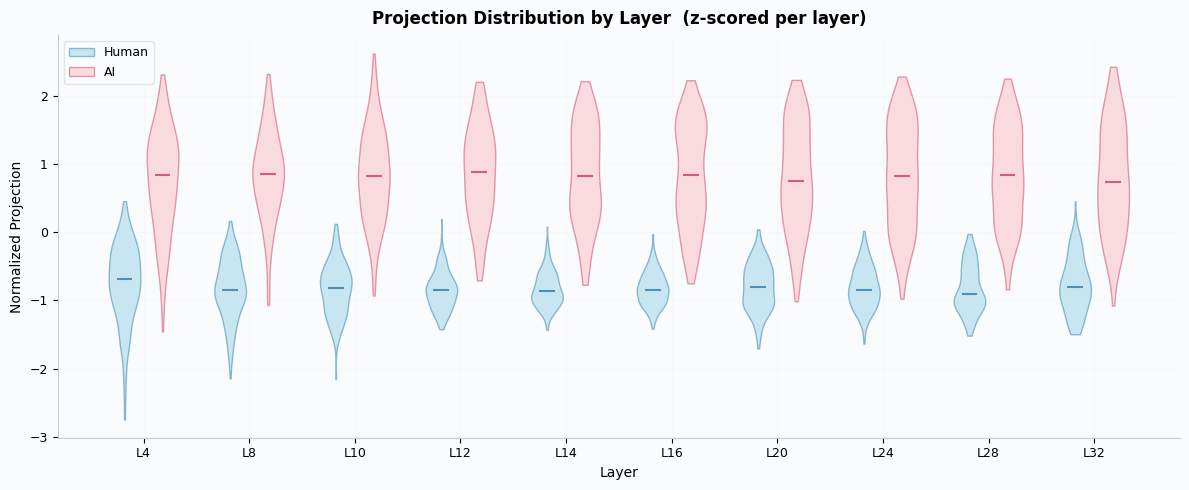

In [11]:
plot_separation_landscape(states, md_models, LAYERS, fig_dir=FIGS);

## B5 · Effect of Steering Strength (Generation Examples)

In [12]:
GEN_DIR = STEER / "generation"

for method_file in sorted(GEN_DIR.glob("generation_*.json")) if GEN_DIR.exists() else []:
    method_name = method_file.stem.replace("generation_", "")
    with open(method_file) as f:
        gen_data = json.load(f)

    print(f"\n{'═'*70}")
    print(f"  Method: {method_name}")
    print(f"{'═'*70}")
    print(f"  α < 0 = toward Human  |  α > 0 = toward AI\n")

    alphas_str = sorted(gen_data[0]["outputs"].keys(), key=float)
    prompts = list(dict.fromkeys(e["prompt"] for e in gen_data))
    chosen_prompt = prompts[0]
    print(f'  Prompt: "{chosen_prompt}"\n')

    for entry in gen_data:
        if entry["prompt"] != chosen_prompt:
            continue
        ly = entry["layer"]
        print(f"  {'─'*66}")
        print(f"  Layer {ly}")
        print(f"  {'─'*66}")
        for a_str in alphas_str:
            a = float(a_str)
            out = entry["outputs"][a_str]
            if isinstance(out, dict):
                direction = out["direction"]
                text = out["text"][:120]
            else:
                direction = "→Human" if a < 0 else ("baseline" if a == 0 else "→AI")
                text = out[:120]
            print(f"    α={a:+5.1f} ({direction:>13})  {text}...")
        print()

if not (GEN_DIR.exists() and list(GEN_DIR.glob("*.json"))):
    # fallback: old format
    old_path = STEER / "generation_results.json"
    if old_path.exists():
        print("(Using legacy generation_results.json)")
        with open(old_path) as f:
            gen_data = json.load(f)
        alphas_str = sorted(gen_data[0]["outputs"].keys(), key=float)
        prompts = list(dict.fromkeys(e["prompt"] for e in gen_data))
        chosen_prompt = prompts[0]
        print(f'Prompt: "{chosen_prompt}"\n')
        for entry in gen_data:
            if entry["prompt"] != chosen_prompt:
                continue
            ly = entry["layer"]
            print(f"{'─'*70}\nLayer {ly}\n{'─'*70}")
            for a_str in alphas_str:
                a = float(a_str)
                label = "→Human" if a < 0 else ("baseline" if a == 0 else "→AI")
                text = entry["outputs"][a_str][:120] if isinstance(entry["outputs"][a_str], str) else entry["outputs"][a_str]["text"][:120]
                print(f"  α={a:+5.1f} ({label:>8})  {text}...")
            print()
    else:
        print("No generation results found — run: python scripts/steering_pipeline.py --multi --method both")

Prompt: "The meaning of life is"

──────────────────────────────────────────────────────────────────────
Layer 12
──────────────────────────────────────────────────────────────────────
  α= -3.0 [ ← Human]   the value or purpose of human existence. The concept of the meaning of life can be very subjective and varies widely depending on one's bel...
  α= -2.0 [ ← Human]   a question that has puzzled philosophers and thinkers for centuries. While there may not be one definitive answer, here are some possible i...
  α= -1.0 [ ← Human]   to be a good person. It's a simple yet profound truth that resonates with many people. However, what does it really mean to be a "good pers...
  α= -0.5 [ ← Human]   to love and be loved, right? And yet, for many people, that’s not enough. If you’ve ever struggled with low self-esteem or a lack of confid...
  α= +0.0 [Baseline]   a question that has puzzled philosophers, theologians, and scholars for centuries. However, the answer to this question can vary

---
# Part C — Denoising Comparison

Compare three validated denoising methods: Raw MeanDiff, NullSpace, Fisher LDA.
All achieve AUC=1.0 — the story is about direction novelty, not discrimination.

## fig09 — Denoising Method Comparison

In [ ]:
if has_ablation:
    plot_denoise_comparison(metrics, LAYERS, method_keys=method_keys, fig_dir=FIGS)
else:
    print("Only one method — skipping denoising plots.")

## fig10 — Projection Violins

In [ ]:
if has_ablation:
    ps_best = states[best_ly]
    h, a = ps_best.human.float(), ps_best.ai.float()
    violin_data = {}
    for mk in method_keys:
        model = all_models.get(mk, {}).get(best_ly)
        if model is None:
            continue
        v = model.get_direction().cpu().float()
        hp = (h @ v).numpy()
        ap = (a @ v).numpy()
        violin_data[mk] = (v, hp, ap)

    if violin_data:
        plot_projection_violins(violin_data, method_keys=method_keys, fig_dir=FIGS)
else:
    print("Skipped — single method.")

---
## Summary

In [ ]:
bm = metrics["methods"]["mean_diff"][str(best_ly)]

print(f"Best layer: L{best_ly}")
print(f"  AUC:      {bm['auc']:.3f}")
print(f"  Accuracy: {bm['accuracy']:.1%}")
print(f"  Hull Norm Dist: {bm.get('hull_centroid_dist_norm', 0):.3f}")
print(f"  Fisher Ratio:   {bm.get('fisher_ratio', 0):.1f}")